In [1]:
from domino.data.data import *
from scipy import stats
from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
import matplotlib.pyplot as plt
from domino.utils.tools import seq_from_df
import pandas as pd
import seaborn as sns
import os

plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'
import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from generic_plotting_functions import *

In [2]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

DNA_context_bin_width=16
DNA_context_length = 200*DNA_context_bin_width


TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

def add_residual_column(df):
    df['residual'] = df['demeaned_ins_score_1'] - df['pred']
    df['abs_residual'] = (df['demeaned_ins_score_1'] - df['pred']).abs()
    
for df in [TRAIN_df, VAL_df, TEST_df]:
    df = add_residual_column(df)
    
genome_path = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6.fa'
genome_fasta = pysam.FastaFile(genome_path)

print(os.listdir(model_dir + '/checkpoint')[0])

model_checkpoint_path = f"{model_dir}/checkpoint/{os.listdir(model_dir + '/checkpoint')[0]}"
model = DominoSingleOutput.load_from_checkpoint(model_checkpoint_path, activation='gelu')
model.eval()

epoch=9-step=83001.ckpt


/home/byw2/micromamba/envs/domino_vis/lib/python3.10/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


fc dim 206
extra dim 6


DominoSingleOutput(
  (activation): GELU(approximate='none')
  (conv0): Sequential(
    (0): Conv1d(4, 512, kernel_size=(5,), stride=(1,), padding=same)
    (1): GELU(approximate='none')
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (convlayers): ModuleList(
    (0): Sequential(
      (0): Conv1d(512, 256, kernel_size=(5,), stride=(1,), padding=same)
      (1): GELU(approximate='none')
      (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): Residual(
      (fn): Sequential(
        (0): Conv1d(256, 256, kernel_size=(5,), stride=(1,), padding=same)
        (1): GELU(approximate='none')
        (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
    (3): Residual(
      (fn): Sequential(
        (0): Conv1d(256, 256, kernel_size=(5,), stride=(1,), padding=same)
        (1): GELU

In [3]:
resolution=200
num_merged=11
delta=2
ws=1
 
data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'
data = fanc.load(f'{data_dir}/mcools/new_nc14_embryo_merged_all_{num_merged}.mcool@{resolution}')

In [4]:
def plot_weights(array, ax, pattern_name, num_seqlets):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    plt.ylim(min(df.sum(axis=1).min(), 0), df.sum(axis=1).max())
    ax.set_title(f'{pattern_name} (num_seqlets={num_seqlets})')

In [5]:
import h5py

ism_dir = os.path.join(model_dir, 'ism_report_1_cutoff')
ism_attr = np.load(os.path.join(model_dir, 'numpy_arrs', 'windowed_attributions.bound_score_gt_1.npy'))

TFMODISCO_WINDOW = 600

print(ism_attr.shape)

# getting all the metadata for each seqlet pattern, including contribution scores, example_idx, start, end, etc.
modisco_results = h5py.File(f"{ism_dir}/modisco_results_{TFMODISCO_WINDOW}bp.h5","r")

seqlets_data = {}
names = ['neg_patterns', 'pos_patterns'] 
for name in names:
    metacluster = modisco_results[name]
    key = lambda x: int(x[0].split("_")[-1])
    for pattern_name, pattern in sorted(metacluster.items(), key=key):
        tag = '{}.{}'.format(name, pattern_name)
        seq_dict = dict()
        for key in pattern['seqlets']:
            seq_dict[key] = pattern['seqlets'][key][:]
        seqlets_data[tag] = seq_dict

modisco_results.close()

(14622, 4, 600)


In [6]:
nc14_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'
nc14_bound_df = pd.read_csv(f'{nc14_model_dir}/final_nc14_boundaries_df.bound_score_gt_1.csv')

## Attribution maps

In [7]:
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 200

from scipy.ndimage import gaussian_filter1d

In [8]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/01_29_2025/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu'

ism_dir = os.path.join(model_dir, 'numpy_arrs')


In [9]:
def sorted_attrs(arr): 
    arr = arr.sum(axis=1)
    row_averages = np.mean(arr, axis=1)
    
    sorted_indices = np.argsort(row_averages)  # Ascending order
    sorted_data = arr[sorted_indices]
    return sorted_data, sorted_indices

ISM min and max
-0.0074 0.0002


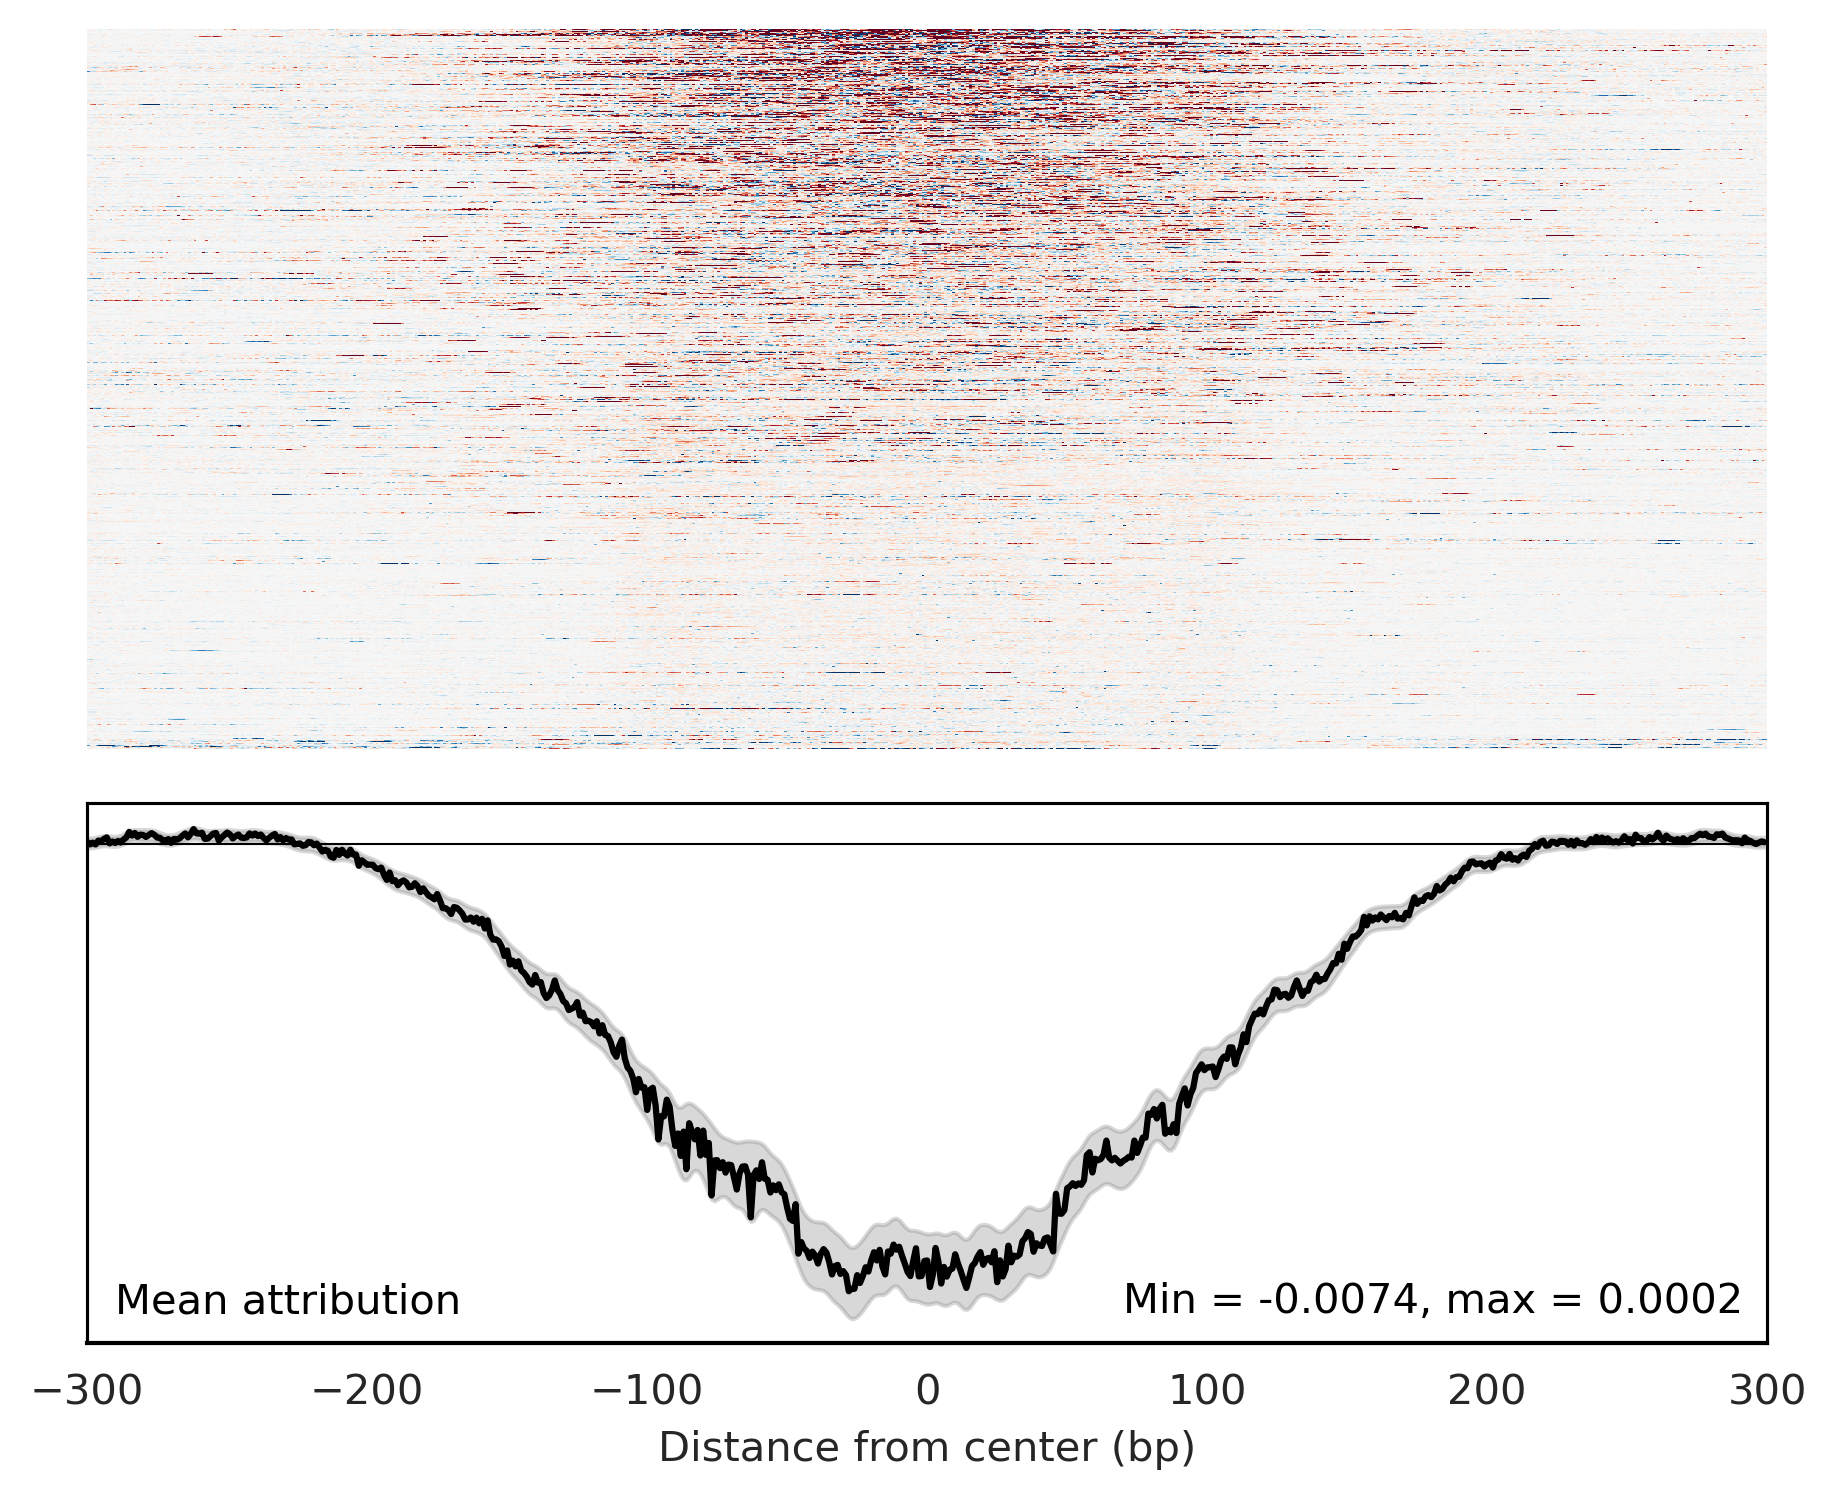

In [10]:
ism_sorted_data, ism_sorted_indices = sorted_attrs(ism_attr)

fig, axs = init_subplots_exact(2,2,dpi=300, y_ratios=[0.6, 0.45], x_ratios=[1.4], yspace=1.1)
ax=axs[0]
sns.heatmap(ism_sorted_data, cmap="RdBu", center=0, cbar=False, vmin=-0.05, vmax=0.05, rasterized=True, ax=axs[0])
ax.set_xticks([])  # Hide x ticks 
ax.set_yticks([])  # Hide x ticks 

ism_sorted_attr, _ = sorted_attrs(ism_attr)
mean_track = ism_sorted_attr.mean(axis=0)
print('ISM min and max')
min_ism, max_ism = round(float(mean_track.min()), 4), round(float(mean_track.max()), 4)
print(min_ism, max_ism)

ism_sorted_attr, _ = sorted_attrs(ism_attr)
mean_track = ism_sorted_attr.mean(axis=0)
std_err = ism_sorted_attr.std(axis=0) / np.sqrt(len(ism_sorted_attr))
units = 2

ax=axs[1]
ax.plot(np.arange(-300, 300), ism_sorted_attr.mean(axis=0), color='black')
ax.axhline(y=0, lw=0.5, color='black')
ax.fill_between(np.arange(-300, 300), 
                gaussian_filter1d(mean_track - units*std_err, sigma=2), 
                gaussian_filter1d(mean_track + units*std_err, sigma=2), 
                alpha=0.3, color='gray')

ax.grid(False)
ax.set_xticks(np.arange(-300, 301, 100))
for spine in ['left', 'bottom', 'right', 'top']:  
    ax.spines[spine].set_color('black')  
    ax.spines[spine].set_linewidth(0.75)  # Decrease spine thickness
    if spine == 'bottom': ax.spines[spine].set_linewidth(1)  # Decrease spine thickness
ax.set_yticks([])  # Hide x ticks  
plt.xlabel("Distance from center (bp)")
plt.text(-290, -0.0078, 'Mean attribution', fontsize=10, color='black')
plt.text(70, -0.0078, f'Min = {min_ism}, max = {max_ism}', fontsize=10, color='black')
plt.xlim(-300, 300)
# plt.savefig("plots/fig2b.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

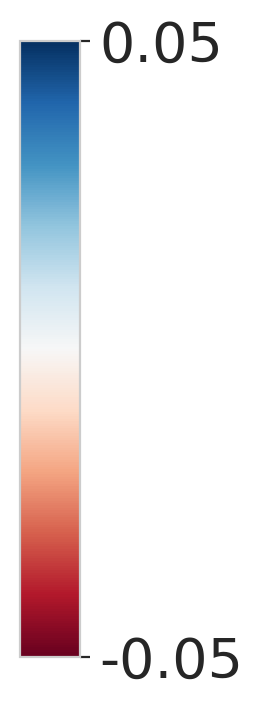

In [11]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Define the colormap and normalization
vmin, vmax = -0.05, 0.05
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
sm = cm.ScalarMappable(cmap='RdBu', norm=norm)
sm.set_array([])
fig, ax = plt.subplots(figsize=(1, 4))
fig.subplots_adjust(left=0.5, right=0.8)
cbar = fig.colorbar(sm, cax=ax, ticks=[vmin, vmax])
cbar.ax.set_yticklabels([vmin, vmax], fontsize=20)
plt.savefig("plots/fig2b_colorbar.pdf", format="pdf")
# plt.show()